In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [42]:
def fondkonto(c0: int, r: float, n_years: int):
    years = np.arange(1, n_years + 1)
    value = np.array([c0 * r**i for i in years])
    tax = 0.3 * value
    value_after_tax = value - tax
    result = pd.DataFrame(
        {
            "year": years,
            "value": value_after_tax.round().astype(int),
            "tax": tax.round().astype(int),
        },
    )
    return result.set_index("year")



def isk(c0, r, n_year, interest_rate=0.0196, no_tax_limit=300000):
    if isinstance(interest_rate, float):
        interest_rate = np.ones(n_years) * interest_rate

    years = np.arange(1, n_years + 1)
    value = np.array([c0 * r**i for i in years])
    taxable_value = np.clip(value - no_tax_limit, 0, None)
    flat_rate_income = taxable_value * (0.01 + interest_rate)
    tax = 0.3 * flat_rate_income
    result = pd.DataFrame(
        {
            "year": years,
            "value": value.round().astype(int),
            "tax": tax.cumsum().round().astype(int),
        }
    )
    return result.set_index("year")

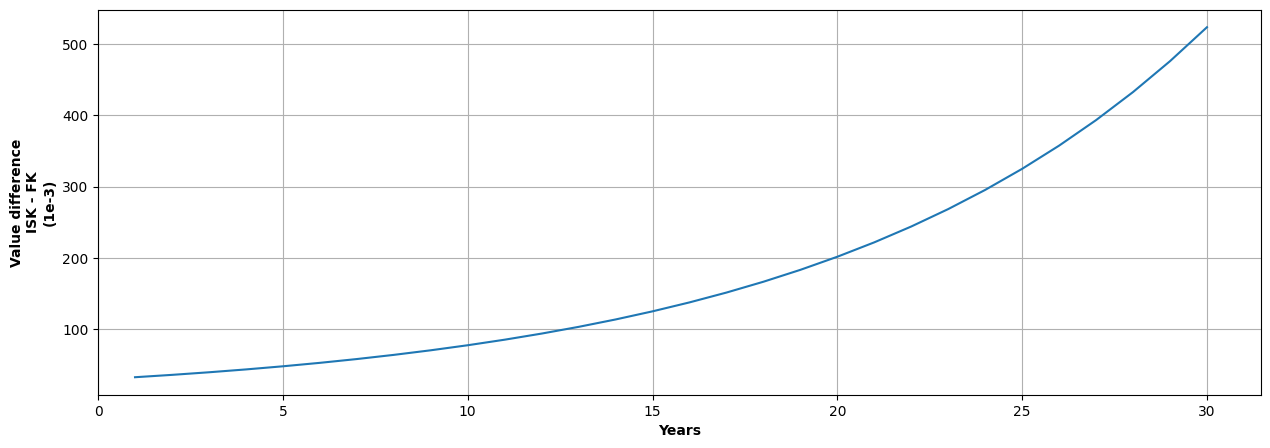

In [79]:
c0 = 100_000
r = 1.1
n_years = 30

df_isk = isk(c0, r, n_years)
df_fk = fondkonto(c0, r, n_years)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df_isk.index, (df_isk["value"] - df_fk["value"]) / 1e3, zorder=3)
ax.grid(zorder=1)
ax.set_xlim(0, None)
ax.set_ylabel("Value difference\nISK - FK\n(1e-3)", fontweight="bold")
ax.set_xlabel("Years", fontweight="bold")
plt.show()
